# Speech recognition

Speech recognition chuyển lời nói thành chữ. Khó khăn chính là hai chuỗi lệch độ dài: ba giây âm thanh ở 16 kHz là 48 000 số, còn câu nói chỉ có năm từ, và dữ liệu không cho biết từ nào ứng với đoạn âm nào. Bài này học CTC, loss huấn luyện được khi chưa biết vị trí từng chữ; cách chấm bằng tỉ lệ lỗi từ (WER); và lỗi hay gặp khi dùng language model sửa câu cho trôi chảy nhưng lại làm sai lời người nói.

> **Mục tiêu**
>
> - Phân biệt CTC và encoder–decoder cho nhận dạng giọng nói.
> - Tính CTC bằng tay và bằng quy hoạch động.
> - Tính WER.
> - Dùng Whisper và kiểm các lỗi hay gặp.

## Một chuỗi âm, một chuỗi chữ, chưa có alignment

Automatic speech recognition (ASR) nhận âm thanh và trả transcript. Nó khác audio classification ở bài 7.2: đáp án là một chuỗi, dài ngắn tùy câu. Đầu vào $X$ có thể là waveform hoặc đặc trưng thời gian–tần số; sau encoder ta có $T$ hidden states, còn transcript là $U$ token. Token có thể là ký tự, subword hoặc từ, tùy model. Thường $T$ lớn hơn $U$ nhiều, và không frame nào được hứa là chứa đúng một chữ.

Alignment (căn chỉnh) là cách gắn các bước âm với những token ấy. Bản ghi thật thường chỉ có transcript toàn clip, không có ranh giới chính xác cho từng token, nên không thể train thẳng một bộ phân loại theo frame. Có hai cách vượt qua:

- **CTC** không chọn một alignment mà cộng xác suất của mọi alignment hợp lệ.
- **Encoder–decoder** sinh token nối tiếp và dùng attention để tự tìm đoạn âm cần đọc cho từng token.

Hai hướng giải quyết chung một khó khăn nhưng khác dạng output và loss; [chương ASR của Jurafsky và Martin](https://web.stanford.edu/~jurafsky/slp3/16.pdf) trình bày cả hai.



**Hỏi nhanh.** Đội có 2000 clip kèm transcript, nhưng không có mốc thời gian của từng ký tự. Một bạn đề xuất chia đều các frame cho các ký tự, rồi train cross-entropy theo frame. Cách này sai ở đâu?

- A. Cross-entropy không dùng được khi có hơn hai lớp
- B. Tốc độ nói không đều, nên nhãn của frame bị gán lệch
- C. Transcript phải đổi sang phiên âm trước khi train
- D. Chia đều chỉ sai với những clip dài hơn 30 giây

<details><summary>Đáp án</summary>

B. Tốc độ nói không đều, nên nhãn của frame bị gán lệch

Người nói kéo dài nguyên âm, ngừng giữa câu, nói nhanh ở những đoạn quen. Chia đều sẽ gán frame im lặng, hoặc frame của chữ bên cạnh, vào sai nhãn, và model học đúng những nhãn sai ấy. CTC tránh việc cố định một alignment bằng cách cộng mọi alignment hợp lệ. Cross-entropy nhiều lớp vẫn dùng bình thường. Phiên âm không bắt buộc. Clip ngắn cũng bị lệch như clip dài.

</details>



## CTC: thêm blank để biểu diễn khoảng chưa xuất chữ

Giả sử bảng nhãn chỉ có chữ `a`. CTC thêm một nhãn blank, ký hiệu `_`, nên mỗi frame có hai xác suất. Một path như `a a _ a` được biến thành transcript bằng **gộp các nhãn giống nhau liền kề trong path, rồi bỏ blank**. Nó thành `aa`; còn `a a a` thành `a`. Blank ở giữa cho phép biểu diễn hai chữ giống nhau liên tiếp, nên không được xóa blank trước khi gộp.

In [ ]:
import numpy as np

def ctc_collapse(path, blank=0):
    result = []
    for step, token in enumerate(path):
        different_from_previous = step == 0 or token != path[step - 1]
        if token != blank and different_from_previous:
            result.append(token)
    return tuple(result)

vocabulary = {0: "_", 1: "a"}
for path in [(1, 1, 0, 1), (1, 1, 1)]:
    transcript = "".join(vocabulary[token] for token in ctc_collapse(path))
    print(" ".join(vocabulary[token] for token in path), "->", transcript)

a a _ a -> aa
a a a -> a


Đó là quy tắc đọc path, chưa phải toàn bộ cách train CTC. Mỗi transcript có thể nhận nhiều path khác nhau. Với xác suất frame $p_t(c)$, xác suất một path $\pi$ là tích $\prod_t p_t(\pi_t)$; xác suất transcript $y$ là tổng trên mọi path collapse về $y$:

$$P(y\mid X)=\sum_{\pi:\mathcal B(\pi)=y}\prod_{t=1}^{T}p_t(\pi_t),\qquad \mathcal L=-\log P(y\mid X).$$

$\mathcal B$ là hàm collapse; chữ $B$ này không phải batch size. Phép tích giả định các frame độc lập **khi đã biết** $X$: mỗi $p_t$ do encoder tính từ cả clip nên vẫn mang ngữ cảnh, nhưng nhãn chọn ở frame này không phụ thuộc nhãn đã chọn ở frame khác.

Khi $T$ lớn, liệt kê mọi path là quá chậm; mục sau cộng chúng bằng dynamic programming. [Bài báo CTC gốc](https://www.cs.toronto.edu/~graves/icml_2006.pdf) là nguồn cho mục tiêu và thuật toán này.

**Hỏi nhanh.** Path `a _ a` collapse thành gì?

- A. `_aa`
- B. `a`
- C. `aa`
- D. Chuỗi rỗng

<details><summary>Đáp án</summary>

C. `aa`

Bước gộp chỉ gộp những nhãn giống nhau **liền kề**. Hai `a` ở đây cách nhau bởi blank, nên được giữ cả hai, và bỏ blank thì còn `aa`. Ra `a` là xóa blank trước rồi mới gộp, đúng thứ tự cần tránh. `_aa` là quên bỏ blank.

</details>

## Cộng đủ các path trên ba frame

Cho ba frame, bảng xác suất theo thứ tự `_`, `a` là $(0.6,0.4)$, $(0.5,0.5)$, $(0.4,0.6)$. Có $2^3=8$ path. `___` cho chuỗi rỗng với xác suất $0.6\cdot0.5\cdot0.4=0.12$; `a_a` cho `aa` với xác suất $0.4\cdot0.5\cdot0.6=0.12$. Sáu path còn lại đều cho `a`, nên $P(a)=1-0.12-0.12=0.76$. Loss cho target `a` là $-\ln0.76$, khoảng 0.2744.

Bảng này đóng vai output softmax của encoder sau ba frame. Code liệt kê đủ tám path và cộng xác suất theo transcript.

In [ ]:
from itertools import product

frame_probabilities = np.array([[0.6, 0.4], [0.5, 0.5], [0.4, 0.6]])
transcript_probabilities = {}
for path in product(range(2), repeat=3):
    probability = np.prod(frame_probabilities[np.arange(3), path])
    transcript = ctc_collapse(path)
    transcript_probabilities[transcript] = transcript_probabilities.get(transcript, 0) + probability
print(f"P(rỗng) = {transcript_probabilities[()]:.3f}")
print(f"P(a) = {transcript_probabilities[(1,)]:.3f}")
print(f"P(aa) = {transcript_probabilities[(1, 1)]:.3f}")
print(f"loss = {-np.log(transcript_probabilities[(1,)]):.4f}")

P(rỗng) = 0.120
P(a) = 0.760
P(aa) = 0.120
loss = 0.2744




Mỗi hàng bên trái là một path cùng xác suất của nó; tám path đổ về ba transcript ở bên phải.

Greedy decoding lấy nhãn xác suất cao nhất ở từng frame rồi collapse. Nó tìm path có xác suất lớn nhất, nhưng transcript cần tìm là transcript có **tổng** xác suất lớn nhất, và một transcript gom nhiều path. Khi một transcript có nhiều path vừa phải còn transcript khác có một path trội, hai đáp án có thể khác nhau. Beam search giữ nhiều tiền tố transcript cùng lúc và cộng xác suất các path dẫn về cùng một tiền tố (prefix beam search), nên gần mục tiêu hơn greedy nhưng tốn thời gian hơn.

**Hỏi nhanh.** Có hai frame, mỗi frame có $P(\_) = 0.6$ và $P(a) = 0.4$. Greedy decoding cho transcript nào, và transcript nào có xác suất lớn nhất?

- A. Greedy cho chuỗi rỗng, còn lớn nhất là `a` với xác suất 0.64
- B. Greedy cho chuỗi rỗng, còn lớn nhất là chuỗi rỗng với xác suất 0.36
- C. Greedy cho `a`, và lớn nhất là `a` với xác suất 0.64
- D. Greedy cho chuỗi rỗng, còn lớn nhất là `aa` với xác suất 0.16

<details><summary>Đáp án</summary>

A. Greedy cho chuỗi rỗng, còn lớn nhất là `a` với xác suất 0.64

Greedy chọn `_` ở cả hai frame. Path `__` có xác suất 0.36 và cho chuỗi rỗng. Nhưng `a` gom ba path `a_`, `_a` và `aa`, tổng là $0.24 + 0.24 + 0.16 = 0.64$. Path `aa` collapse thành `a`, không thành `aa`. Muốn ra `aa` thì cần ít nhất ba frame. Coi path tốt nhất là transcript tốt nhất là nhầm giữa hai bài toán tìm kiếm khác nhau.

</details>



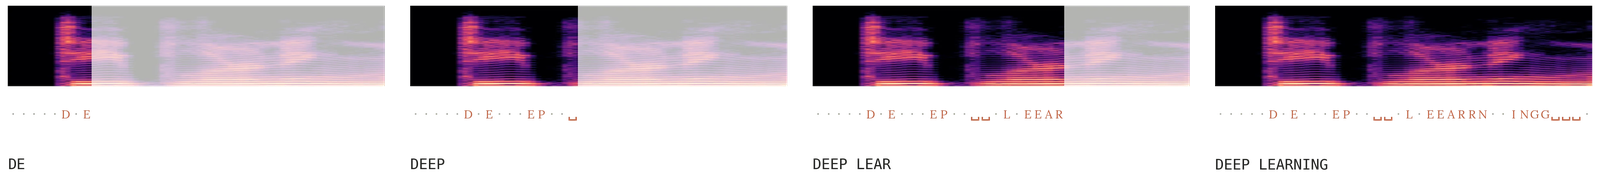

## Cộng mọi path bằng dynamic programming

Liệt kê phải duyệt $C^T$ path: 8 path ở ví dụ trên, nhưng $30^{100}$ path với 30 nhãn và 100 frame. Cách cộng nhanh giống bài đếm đường đi trên lưới.

Chèn blank vào đầu, cuối và giữa mọi nhãn của target để được chuỗi mở rộng $\ell'=(\_,y_1,\_,y_2,\dots,y_U,\_)$ dài $2U+1$. Mỗi path hợp lệ là một đường đi qua lưới gồm frame $t$ và vị trí $s$ trong $\ell'$. Sang frame kế tiếp, đường đi có ba lựa chọn:

- đứng yên (kéo dài nhãn hiện tại);
- tiến một ô;
- nhảy qua một blank để sang nhãn sau.

Bước nhảy chỉ được phép khi nhãn mới khác nhãn cũ; nếu không, hai nhãn giống nhau đứng sát nhau sẽ bị gộp làm một.

Gọi $\alpha_t(s)$ là tổng xác suất của mọi đoạn path dài $t$ dừng ở vị trí $s$:

$$\begin{aligned}\alpha_t(s)=\Big(&\alpha_{t-1}(s)+\alpha_{t-1}(s-1)\\&+\big[\ell'_s\neq\_,\ \ell'_s\neq\ell'_{s-2}\big]\,\alpha_{t-1}(s-2)\Big)\,p_t(\ell'_s).\end{aligned}$$

Dấu ngoặc vuông bằng 1 khi cả hai điều kiện đúng, bằng 0 nếu không. Path bắt đầu bằng blank đầu hoặc nhãn đầu, nên $\alpha_1(1)=p_1(\_)$, $\alpha_1(2)=p_1(y_1)$, các ô khác bằng 0. Path phải dừng ở nhãn cuối hoặc blank cuối, nên $P(y\mid X)=\alpha_T(2U+1)+\alpha_T(2U)$. Lưới có $T(2U+1)$ ô, mỗi ô cộng tối đa ba số: thời gian $O(TU)$ thay cho $C^T$.

In [ ]:
def ctc_forward(frame_probabilities, target, blank=0):
    extended = [blank]
    for token in target:
        extended += [token, blank]
    alpha = np.zeros(len(extended))
    alpha[0] = frame_probabilities[0, blank]
    alpha[1] = frame_probabilities[0, extended[1]]
    history = [alpha]
    for t in range(1, len(frame_probabilities)):
        previous, alpha = alpha, np.zeros(len(extended))
        for s, label in enumerate(extended):
            total = previous[s]
            if s >= 1:
                total += previous[s - 1]
            if s >= 2 and label != blank and label != extended[s - 2]:
                total += previous[s - 2]
            alpha[s] = total * frame_probabilities[t, label]
        history.append(alpha)
    return alpha[-1] + alpha[-2], history

probability_a, history = ctc_forward(frame_probabilities, [1])
for t, row in enumerate(history, start=1):
    print(f"t={t}:", "  ".join(f"{value:.2f}" for value in row))
print(f"P(a) = {probability_a:.2f}")

t=1: 0.60  0.40  0.00
t=2: 0.30  0.50  0.20
t=3: 0.12  0.48  0.28
P(a) = 0.76


Ba cột ứng với `_ a _`. Ở $t=2$, ô `a` nhận $0.4$ (đã ở `a`) cộng $0.6$ (từ blank đầu), nhân $p_2(a)=0.5$ được $0.5$. Hàng cuối cộng hai ô cuối: $0.48+0.28=0.76$, đúng tổng của sáu path đã liệt kê. Ô đầu hàng cuối, $0.12$, là path toàn blank, tức $P(\text{rỗng})$.



Code trên nhân xác suất thường cho dễ đọc. Thư viện chạy cùng truy hồi trong log-space: lưu $\log\alpha$ và thay mỗi phép cộng bằng $\log\sum\exp$ (logsumexp), vì tích của hàng trăm xác suất nhỏ nhanh chóng vượt khỏi khoảng số mà máy biểu diễn được.

**Hỏi nhanh.** Một bạn viết đúng truy hồi ở trên, nhưng bằng xác suất thường, cho một clip 1000 frame, xác suất mỗi frame quanh 0.1. Loss in ra `inf`, dù target ngắn và lengths đủ. Nguyên nhân là gì, và sửa thế nào?

- A. T quá dài so với target nên mất path hợp lệ, cần cắt bớt frame
- B. Tích $10^{-1000}$ tràn dưới thành 0, cần chuyển sang log-space
- C. Sai số làm tròn cộng dồn qua 1000 bước, cần đổi sang `float32`
- D. Bảng xác suất chưa chuẩn hóa, cần chia mỗi hàng cho tổng của nó

<details><summary>Đáp án</summary>

B. Tích $10^{-1000}$ tràn dưới thành 0, cần chuyển sang log-space

$0.1^{1000} = 10^{-1000}$ nhỏ hơn số dương nhỏ nhất của `float64`, cỡ $10^{-308}$, và kể cả số subnormal cũng chỉ tới cỡ $10^{-324}$. Vì vậy tích thành 0, và $-\log 0 = \infty$. Trong log-space, $\log\alpha$ chỉ cỡ $-2300$, biểu diễn thoải mái. T dài hơn chỉ thêm path chứ không làm mất path. `float32` còn tràn sớm hơn, quanh $10^{-38}$. Bảng đã chuẩn hóa vẫn cho tích nhỏ như vậy.

</details>



PyTorch có `CTCLoss` làm đúng phép cộng này trong log-space. Nó nhận **log probabilities** shape `(T,B,C)`: thời gian trước, batch sau, khác Conv2d và nhiều model đặt batch trước. Ta dùng `reduction='sum'` để đối chiếu trực tiếp $-\log P(a)$; mặc định `'mean'` còn chia loss mỗi mẫu cho độ dài target trước khi lấy trung bình batch.

In [ ]:
import torch

log_probabilities = torch.tensor(frame_probabilities, dtype=torch.float64).log()[:, None, :]
criterion = torch.nn.CTCLoss(blank=0, reduction="sum")
target = torch.tensor([1], dtype=torch.long)
loss = criterion(
    log_probabilities,
    target,
    torch.tensor([3]),
    torch.tensor([1]),
)
print(tuple(log_probabilities.shape))
print(f"CTCLoss = {loss.item():.4f}")
too_short_loss = criterion(
    log_probabilities[:2],
    torch.tensor([1, 1]),
    torch.tensor([2]),
    torch.tensor([2]),
)
print(f"target aa, 2 frame: inf = {bool(torch.isinf(too_short_loss))}")

(3, 1, 2)
CTCLoss = 0.2744
target aa, 2 frame: inf = True


Thêm một phép kiểm trên bảng ngẫu nhiên 12 frame, 4 nhãn, với target `1 2 2 3` có hai nhãn giống nhau đứng liền nhau, đúng trường hợp bước nhảy bị cấm:

In [ ]:
rng = np.random.default_rng(0)
random_logits = rng.normal(size=(12, 4))
random_probabilities = np.exp(random_logits) / np.exp(random_logits).sum(axis=1, keepdims=True)
random_target = [1, 2, 2, 3]
dp_loss = -np.log(ctc_forward(random_probabilities, random_target)[0])
torch_loss = criterion(
    torch.tensor(random_probabilities).log()[:, None, :],
    torch.tensor(random_target),
    torch.tensor([12]),
    torch.tensor([4]),
)
print(f"DP = {dp_loss:.6f}, CTCLoss = {torch_loss.item():.6f}")

DP = 10.588453, CTCLoss = 10.588453


Hai cách cho cùng một số đến sáu chữ số thập phân: truy hồi vừa viết tính đúng điều `CTCLoss` tính.

Dòng cuối của khối `CTCLoss` đầu tiên cho `inf`: target `aa` cần ít nhất ba bước, `a _ a`, vì hai `a` liền nhau cần một blank chen giữa. Tổng quát, target dài $U$ có $r$ cặp nhãn giống nhau đứng liền nhau cần ít nhất $U+r$ bước sau encoder; $U\leq T$ là điều kiện cần nhưng chưa đủ. `zero_infinity=True` đặt các loss vô hạn về 0 để chúng không làm hỏng gradient, nhưng không sửa alignment thiếu bước.

Nếu nhiều mẫu rơi vào tình huống ấy, kiểm lengths sau encoder, tốc độ downsampling và tokenization. [Tài liệu `CTCLoss`](https://docs.pytorch.org/docs/2.9/generated/torch.nn.CTCLoss.html) ghi rõ shape, lengths và ý nghĩa reduction.

**Hỏi nhanh.** Khối `CTCLoss` ở trên cho target `aa` với chỉ hai frame. Vì sao loss là `inf`?

- A. Vì CTC không biểu diễn được hai chữ giống nhau liền nhau
- B. Vì target phải ghi blank giữa hai `a` mà lại thiếu
- C. Vì mỗi nhãn cần ít nhất hai frame, tổng cộng là bốn
- D. Vì hai `a` liền nhau cần blank chen giữa, tối thiểu 3 bước

<details><summary>Đáp án</summary>

D. Vì hai `a` liền nhau cần blank chen giữa, tối thiểu 3 bước

`a a` collapse thành `a`, chỉ `a _ a` mới thành `aa`. Vì vậy cần $U + r = 2 + 1 = 3$ bước. Với hai bước, không đường nào trên lưới đi tới được cuối chuỗi mở rộng. CTC vẫn biểu diễn được chữ lặp, chỉ cần thêm bước. Blank nằm trong path, không bao giờ nằm trong target. Một nhãn có thể chiếm đúng một frame.

</details>



## Encoder–decoder: sinh từng token với ngữ cảnh đã sinh

Hướng thứ hai dùng encoder cho âm thanh và decoder sinh transcript từng token:

$$P(y\mid X)=\prod_{u=1}^{U}P(y_u\mid y_{<u},X).$$

$y_{<u}$ là các token trước vị trí $u$. Khi train, decoder nhận transcript thật dịch phải một vị trí (teacher forcing, bài 6.5) và causal mask chặn mỗi vị trí đọc token phía sau; khi suy luận, nó nhận lại chính các token vừa sinh. Decoder đọc encoder bằng cross-attention, nên không cần xuất token ở từng frame và không dùng quy tắc blank của CTC. Câu kết thúc khi decoder sinh token hết câu, không phải khi hết frame.

[Whisper](https://arxiv.org/abs/2212.04356) là một Transformer encoder–decoder theo hướng này. Các bước của Whisper:

1. Audio được resample về 16 kHz, cắt hoặc pad thành cửa sổ 30 giây, rồi đổi thành log-mel với cửa sổ 25 ms, bước 10 ms: 3000 frame.
2. Hai lớp convolution đầu encoder, lớp thứ hai có stride 2, còn lại 1500 vị trí.
3. Decoder bắt đầu bằng một dãy token đặc biệt chỉ định việc cần làm: `<|startoftranscript|>`, token ngôn ngữ như `<|vi|>`, rồi `<|transcribe|>` để chép lời hoặc `<|translate|>` để dịch sang tiếng Anh.

Processor đi kèm checkpoint làm phần đổi audio thành đặc trưng và đổi token thành chữ; thay nó bằng log-mel tự tính theo bài 7.1 sẽ lệch thang số so với lúc model được train.

Decoder mang kiến thức ngôn ngữ nên chọn được câu có nghĩa khi âm mờ, nhưng cũng có thể sinh chữ không có trong âm thanh. Với clip im lặng hoặc toàn nhiễu, nó vẫn sinh một chuỗi nào đó, đôi khi lặp một cụm nhiều lần. [Model card Whisper](https://huggingface.co/openai/whisper-tiny) ghi rõ hiện tượng hallucination này và chênh lệch chất lượng giữa các ngôn ngữ, miền dữ liệu; độ chính xác trên bản ghi tiếng Việt của một bài thi chỉ biết được khi chấm trên validation của chính bài đó.

Các model audio-language như [Qwen2-Audio](https://huggingface.co/docs/transformers/model_doc/qwen2_audio) và [Voxtral](https://huggingface.co/mistralai/Voxtral-Mini-3B-2507) nhận thêm chỉ dẫn bằng chữ để trả lời về âm thanh. Chỉ dẫn “chép nguyên lời nói” và “tóm tắt clip” cho hai output khác hẳn nhau, nên prompt phải khớp task của đề. Processor, chat template và checkpoint đi theo từng kiến trúc và phiên bản thư viện: đổi tên model trong một script viết cho Whisper không làm script ấy chạy được với kiến trúc khác.

**Hỏi nhanh.** Với một clip tiếng Việt, Whisper trả về câu tiếng Anh trôi chảy, đúng ý người nói. WER so với reference tiếng Việt gần bằng 1. Nên kiểm gì trước?

- A. Beam size quá nhỏ nên decoder chọn nhầm ngôn ngữ
- B. Reference có dấu tiếng Việt, còn output thì không
- C. Dãy token khởi đầu đang chọn task `<|translate|>`
- D. Sample rate 16 kHz quá thấp cho tiếng Việt

<details><summary>Đáp án</summary>

C. Dãy token khởi đầu đang chọn task `<|translate|>`

Câu tiếng Anh đúng ý cho thấy model đã nghe đúng, nhưng đang làm task dịch. Khi sinh, hãy đặt rõ `task="transcribe"` và ngôn ngữ tiếng Việt, đừng để model tự đoán. Beam size chỉ đổi cách tìm trong cùng một task. Bỏ dấu không biến câu tiếng Anh thành câu tiếng Việt. 16 kHz chính là sample rate mà Whisper được train.

</details>



## WER: chấm transcript bằng edit distance

Một câu dự đoán có thể thiếu từ, thêm từ hoặc thay từ. Word error rate là

$$\operatorname{WER}=\frac{S+D+I}{N_{\mathrm{ref}}},$$

với $S$ là số substitution, $D$ deletion, $I$ insertion trong một alignment tối ưu, và $N_{\mathrm{ref}}$ là số token tham chiếu. Ta tìm tổng lỗi nhỏ nhất bằng Levenshtein distance, giống dynamic programming chuỗi trong lập trình thi đấu. Hàng biểu diễn prefix của reference, cột biểu diễn prefix của prediction; mỗi ô chọn xóa, chèn, thay hoặc giữ token.

Trong code dưới, token là phần tách bởi khoảng trắng sau khi đưa Unicode về dạng NFC và chuyển chữ thường. Bước NFC đã gặp ở bài 6.1: cùng một chữ có dấu như `ọ` có thể lưu theo hai cách, hiển thị giống hệt nhau nhưng so chuỗi thì khác. Tách khoảng trắng cũng không phải tách từ theo ngôn ngữ học: “lập trình” là một từ nhưng hai token.

Khi chấm thật, tokenizer và cách chuẩn hóa (chữ hoa, dấu câu, số, Unicode) phải theo đúng scorer của đề và áp dụng cho cả reference lẫn prediction; tự bỏ dấu tiếng Việt để điểm đẹp hơn là đổi metric.

Character error rate (CER) dùng cùng công thức trên ký tự; một từ sai một dấu bị CER phạt một ký tự, còn WER phạt cả từ. Câu đúng 10 từ, bản nhận dạng thay 1, thiếu 1, thừa 1 từ có WER $3/10 = 0.3$. OCR được chấm cùng cách: “xin chào” đọc thành “xin chao” sai 1 trên 8 ký tự, CER 0.125. Với tiếng Việt, dấu thanh và dấu phụ chỉ là vài pixel nên OCR dễ nhầm, mà sai một dấu là đổi nghĩa.

In [ ]:
import unicodedata

def word_tokens(text):
    return unicodedata.normalize("NFC", text).lower().split()

def edit_distance(reference_tokens, predicted_tokens):
    previous = list(range(len(predicted_tokens) + 1))
    for row, reference_token in enumerate(reference_tokens, start=1):
        current = [row]
        for column, predicted_token in enumerate(predicted_tokens, start=1):
            deletion = previous[column] + 1
            insertion = current[column - 1] + 1
            substitution = previous[column - 1] + (reference_token != predicted_token)
            current.append(min(deletion, insertion, substitution))
        previous = current
    return previous[-1]

reference = word_tokens("em học AI hôm nay")
prediction = word_tokens("em học toán nay")
errors = edit_distance(reference, prediction)
print(f"lỗi = {errors}, token tham chiếu = {len(reference)}")
print(f"WER = {errors / len(reference):.3f}")

lỗi = 2, token tham chiếu = 5
WER = 0.400




Tính tay: thay `ai` bằng `toán`, xóa `hôm`, giữ `em học ... nay`: hai lỗi trên năm token, WER 0.4. DP chỉ giữ hai hàng nên bộ nhớ $O(|\text{prediction}|)$, thời gian $O(N_{\mathrm{ref}}N_{\mathrm{pred}})$.

Muốn chỉ rõ từng lỗi, lưu backpointer để khôi phục một alignment tối ưu; có thể có nhiều alignment cùng tổng lỗi. Số lỗi chèn có thể nhiều hơn số từ tham chiếu, nên WER có thể lớn hơn 1; nó không phải accuracy nằm trong $[0,1]$.



**Hỏi nhanh.** Reference có 4 token. Prediction giữ đúng cả 4 token ấy và chèn thêm 5 token. WER bằng bao nhiêu?

- A. 0
- B. 0.56
- C. 1
- D. 1.25

<details><summary>Đáp án</summary>

D. 1.25

Không có substitution hay deletion. 5 token thừa là 5 insertion, nên WER bằng $5/4 = 1.25$. 0 là chỉ đếm token đúng. 0.56 là chia nhầm cho 9 token của prediction. 1 là tưởng WER bị chặn trên như accuracy.

</details>

**Hỏi nhanh.** Reference là `mai thi`, prediction là `thi đấu`. Hai đội cài cùng một DP, nhưng phá hòa khác nhau khi lần backpointer. Một đội báo 2 substitution, đội kia báo 1 deletion và 1 insertion. WER trong hai báo cáo là bao nhiêu?

- A. Đội đầu 1.0, đội sau 0.5 vì giữ được `thi`
- B. Đội đầu 0.5, đội sau 1.0 vì thay thế nhẹ hơn
- C. Cả hai đều 1.0, vì tổng lỗi tối ưu chỉ có một
- D. Không xác định được, vì alignment không duy nhất

<details><summary>Đáp án</summary>

C. Cả hai đều 1.0, vì tổng lỗi tối ưu chỉ có một

Hai alignment đều tốn 2 phép. Một là thay `mai` bằng `thi` và thay `thi` bằng `đấu`. Hai là xóa `mai`, giữ `thi`, chèn `đấu`. Edit distance là giá trị nhỏ nhất, nên chỉ có một, và WER bằng $2/2 = 1.0$. Chỉ cách chia thành S, D, I mới phụ thuộc cách phá hòa. Giữ được `thi` không làm giảm số phép. WER cũng không coi substitution nhẹ hơn deletion. Khi báo cáo S, D, I, hãy ghi rõ quy tắc phá hòa.

</details>

## Gộp toàn tập, rồi đọc loại lỗi

Corpus WER cộng tổng số lỗi của các câu rồi chia tổng số token tham chiếu. Nó không bằng trung bình đơn giản WER từng câu. Một câu ngắn sai một từ và một câu dài đúng hết không được cân bằng nhau nếu metric là corpus WER.

In [ ]:
references = ["em học AI", "mai lớp em học lập trình thi đấu"]
predictions = ["em học", "mai lớp em học lập trình thi đấu"]
error_counts = [edit_distance(word_tokens(r), word_tokens(p)) for r, p in zip(references, predictions)]
lengths = [len(word_tokens(r)) for r in references]
corpus_wer = sum(error_counts) / sum(lengths)
mean_sentence_wer = np.mean([e / n for e, n in zip(error_counts, lengths)])
print(error_counts, lengths)
print(f"corpus WER = {corpus_wer:.3f}")
print(f"mean sentence WER = {mean_sentence_wer:.3f}")

[1, 0] [3, 8]
corpus WER = 0.091
mean sentence WER = 0.167


Một lỗi trên $3+8=11$ token cho khoảng 0.091; trung bình $(1/3+0)/2$ khoảng 0.167. Corpus WER cân theo số token, còn trung bình câu cân mỗi câu như nhau nên câu ngắn nặng ký hơn. Đề ghi metric nào thì chọn model theo đúng metric đó.



**Hỏi nhanh.** Validation có một câu 4 token và một câu 36 token. Model A sai 2 token ở câu ngắn, đúng hết câu dài. Model B đúng hết câu ngắn, sai 6 token ở câu dài. Corpus WER và trung bình WER từng câu chọn model nào?

- A. Corpus chọn B, trung bình câu chọn A
- B. Corpus chọn A, trung bình câu chọn B
- C. Cả hai cách đều chọn A
- D. Cả hai cách đều chọn B

<details><summary>Đáp án</summary>

B. Corpus chọn A, trung bình câu chọn B

Theo corpus, A có $2/40 = 0.05$, B có $6/40 = 0.15$. Theo trung bình câu, A có $(0.5 + 0)/2 = 0.25$, B có $(0 + 6/36)/2 \approx 0.083$. Khi lấy trung bình theo câu, một lỗi ở câu 4 token nặng gấp chín lần một lỗi ở câu 36 token. Hãy chọn model theo đúng phép gộp mà scorer của đề dùng.

</details>

Clip có reference rỗng, như đoạn im lặng hay chỉ có nhạc, làm WER của riêng câu đó chia cho 0. Corpus WER vẫn tính được khi tổng token reference dương: mọi từ model sinh cho clip ấy là insertion cộng vào tử số. Vì vậy không âm thầm bỏ các clip này khỏi validation; đó chính là chỗ decoder dễ sinh chữ không có trong âm thanh.

Ngoài điểm tổng, chia lỗi theo người nói, thời lượng, tiếng nền, tên riêng và số. Một model có WER thấp hơn vẫn có thể chép sai số phòng hay ngày giờ mà ứng dụng cần. Đọc vài alignment S/D/I là cách nối metric với lỗi thật trước khi đổi checkpoint hay tăng beam size.

**Hỏi nhanh.** Ba clip có tổng cộng 20 token reference và 2 lỗi. Clip thứ tư im lặng, reference rỗng, nhưng model sinh ra 4 từ “cảm ơn đã xem”. Corpus WER của cả bốn clip bằng bao nhiêu?

- A. Không tính được, vì chia cho 0
- B. 0.10
- C. 0.25
- D. 0.30

<details><summary>Đáp án</summary>

D. 0.30

Clip im lặng góp 4 insertion vào tử số, và 0 vào mẫu số. Vậy WER là $(2 + 4)/20 = 0.30$. 0.10 là kết quả khi lặng lẽ bỏ clip ấy đi. 0.25 là chia nhầm cho $20 + 4$, tức đếm cả token của prediction. Chỉ WER của riêng clip im lặng mới chia cho 0. Corpus WER vẫn xác định khi tổng token reference dương.

</details>

## Nối ASR với language model: đo trước và sau

Có thể dùng language model thêm dấu câu hoặc sửa lỗi nghe, nhưng mục tiêu vẫn là giữ đúng nội dung bản ghi. Câu trôi chảy hơn không đồng nghĩa WER thấp hơn. Xét một trường hợp: reference và transcript gốc đều là `mai thi ai`; bước “sửa” đổi nó thành `mai thi toán`, một câu cũng rất tự nhiên. Đưa cả hai transcript qua cùng scorer:

In [ ]:
reference_text = "mai thi ai"
original_text = "mai thi ai"
edited_text = "mai thi toán"
reference_tokens = word_tokens(reference_text)
for name, text in [("gốc", original_text), ("sửa", edited_text)]:
    error_count = edit_distance(reference_tokens, word_tokens(text))
    print(f"{name}: WER = {error_count / len(reference_tokens):.3f}")

gốc: WER = 0.000
sửa: WER = 0.333


Hậu xử lý làm WER từ 0 lên 0.333 vì đổi tên môn.

Khi thử một prompt sửa ASR, giữ transcript gốc, lưu phiên bản prompt và model, rồi so cặp trước và sau trên cùng validation. Chỉ dẫn hẹp như “giữ nguyên từ, chỉ thêm dấu câu” hợp khi đó đúng là nhiệm vụ, nhưng vẫn phải kiểm vì model có thể không tuân thủ. Scorer bỏ dấu câu thì thêm dấu câu không làm WER tốt hơn.

**Hỏi nhanh.** Reference là `phòng mười lăm`. ASR ra `phòng mười năm`, rồi language model sửa thành `phòng 15`, đúng ý người nói. Scorer viết thường, tách theo khoảng trắng, và không chuẩn hóa số. WER trước và sau khi sửa là bao nhiêu?

- A. 0.333, rồi tăng lên 0.667
- B. 0.333, rồi giảm về 0
- C. 0.333, rồi giữ nguyên 0.333
- D. 0.667, rồi giảm về 0.333

<details><summary>Đáp án</summary>

A. 0.333, rồi tăng lên 0.667

Trước khi sửa có một substitution, `năm` thay `lăm`, trên 3 token, nên WER là $1/3$. Sau khi sửa, `15` thay `mười` là một substitution, và `lăm` bị xóa, nên WER là $2/3$. Với scorer này, đúng ý chưa phải là đúng token. Nếu scorer không đổi số, chỉ dẫn cho language model phải giữ số ở dạng chữ. Nghĩ WER về 0 là ngầm cho rằng scorer chuẩn hóa số.

</details>

## Chạy Whisper trên dữ liệu thật

[Script của chương](recipes/README.md) đưa quy trình trên vào lệnh `local_audio.py --task asr`. Đầu vào là một thư mục checkpoint Whisper có sẵn trên máy và một tệp JSON liệt kê dữ liệu; mỗi bản ghi gồm ID, đường dẫn WAV, reference, nhóm (người nói hoặc phiên thu) và split. Hai bước:

1. `--check` kiểm từng file, loại model, processor, sample rate và hash mà không nạp trọng số.
2. `--run` nạp model bằng `local_files_only=True`, chép lời từng clip validation trên CPU với `task="transcribe"` và ngôn ngữ đã chọn, rồi ghi tệp kết quả `receipt.json`: transcript, số lỗi và số token reference của từng clip, cờ clip im lặng, thời gian suy luận và corpus WER.

Scorer của script là chữ thường cộng tách khoảng trắng; đề chuẩn hóa khác thì sửa scorer trước khi so model. Đọc kết quả theo thứ tự: corpus WER, rồi các clip nhiều lỗi nhất và các clip im lặng có chữ, rồi thời gian suy luận mỗi clip để ước lượng thời gian chạy hết tập test.

Script chỉ nhận clip không quá 30 giây, đúng một cửa sổ của Whisper, và dừng kèm thông báo khi gặp clip dài hơn. Clip dài cần chia đoạn: cắt theo khoảng lặng bằng voice activity detection (VAD), hoặc cắt cửa sổ có phần chồng nhau, giữ timestamp của từng đoạn rồi mới ghép transcript. Nối chuỗi mù các đoạn có phần chồng sẽ chép hai lần các từ trong vùng chồng; cắt không chồng lại dễ cắt đôi một từ ở ranh giới. Sau khi ghép, đọc alignment quanh các ranh giới trên validation.

**Hỏi nhanh.** Trên một clip 30 giây, Whisper chép mất 6 giây. Test có 1500 clip, mỗi clip 3 giây. Một bạn ước thời gian là $1500\cdot 6\cdot 3/30 = 900$ giây. Ước lượng này sai ở đâu?

- A. Không sai, vì thời gian tỉ lệ thuận với thời lượng audio
- B. Mỗi clip được pad lên 30 giây, nên phần encoder không giảm
- C. Thời gian chỉ phụ thuộc số token, nên phải nhân theo số từ
- D. Còn thiếu thời gian resample, phần tốn nhất của pipeline

<details><summary>Đáp án</summary>

B. Mỗi clip được pad lên 30 giây, nên phần encoder không giảm

Processor đưa mọi clip về một cửa sổ 30 giây, tức 3000 frame. Encoder vì vậy làm cùng một lượng tính cho clip 3 giây và clip 30 giây, chỉ có phần decoder ngắn đi vì ít token hơn. Thời gian mỗi clip ngắn vì thế giảm ít hơn 10 lần, và 900 giây là ước lượng quá lạc quan. Hãy đo trực tiếp trên vài clip có độ dài giống test. Số token chỉ quyết định phần decoder. Resample bằng `resample_poly` rẻ so với chạy model.

</details>



## Khi đi thi

- Viết scorer local cho ra đúng điểm trên ví dụ của đề: chữ hoa, dấu câu, số được chuẩn hóa thế nào.
- Đo thời gian trên vài clip giống test rồi nhân lên; Whisper pad mọi clip lên 30 giây.
- Train CTC thì kiểm độ dài trước: mỗi mẫu cần đủ frame sau encoder, loss `inf` là lỗi dữ liệu.

## Tóm tắt

- ASR nối chuỗi âm dài với transcript ngắn khi chưa có alignment. CTC cộng mọi alignment có blank; encoder–decoder sinh từng token theo ngữ cảnh, theo task và ngôn ngữ đã chỉ định.
- Collapse gộp nhãn lặp liền kề rồi mới bỏ blank. Path tốt nhất của greedy chưa chắc cho transcript có tổng xác suất lớn nhất.
- Truy hồi $\alpha$ trên chuỗi mở rộng dài $2U+1$ cộng mọi path trong $O(TU)$ và chạy trong log-space; target cần ít nhất $U+r$ bước sau encoder.
- WER là edit distance chia số token reference, có thể lớn hơn 1. Normalization theo đúng scorer; corpus WER gộp lỗi và token, khác trung bình từng câu, và không bỏ clip im lặng.
- Hậu xử lý bằng language model và chunking clip dài đều phải được chấm trước và sau trên cùng validation.

## Kiểm tra cuối bài

**Câu 1.** Đề yêu cầu transcript cho từng clip. Baseline của đội chỉ trả nhãn `có tiếng nói` hoặc `không tiếng nói` cho mỗi clip. Phần nào chưa đáp ứng nhiệm vụ?

- A. Hợp đồng output, vì cần một chuỗi token cho mỗi clip
- B. Thiết bị, vì ASR bắt buộc phải chạy trên GPU
- C. Loss, vì transcript phải được train bằng MSE
- D. Sample rate, vì nhãn clip cần sample rate cao hơn

<details><summary>Đáp án</summary>

A. Hợp đồng output, vì cần một chuỗi token cho mỗi clip

Phát hiện có tiếng nói, tức voice activity detection, và chép nội dung là hai nhiệm vụ khác nhau. Một nhãn cho cả clip không chứa transcript, dù có thể làm bước lọc trong pipeline. ASR chạy được trên CPU. Không có loss nào bắt buộc phải là MSE. Sample rate cũng không biến nhãn clip thành chuỗi chữ.

</details>

**Câu 2.** CTC path là `a a _ b b _ b`, trong đó `_` là blank. Gộp các nhãn lặp liền nhau trước, rồi bỏ blank, thì được transcript nào?

- A. `aabbb`
- B. `a_b_b`
- C. `ab`
- D. `abb`

<details><summary>Đáp án</summary>

D. `abb`

Gộp các nhãn lặp liền kề: `a a` thành `a`, `b b` thành `b`, được `a _ b _ b`. Bỏ blank thì được `abb`. Hai `b` cuối cách nhau bởi blank, nên là hai lần phát âm. `ab` là kết quả của việc bỏ blank trước rồi mới gộp. `aabbb` là quên gộp. `a_b_b` là quên bỏ blank.

</details>

**Câu 3.** Train một model CTC từ đầu. Sau 50 epoch, loss vẫn dao động mạnh, và thỉnh thoảng có batch cho `inf`. Nên chẩn đoán theo thứ tự nào trước?

- A. Kiểm dữ liệu, gồm target có lẫn blank không và lengths sau encoder, rồi tới đầu vào của loss
- B. Kiểm luồng gradient bằng `autograd.grad`, xem độ cong của mặt loss, rồi giảm learning rate
- C. Theo dõi norm gradient từng lớp, chạy LR range test, rồi xem trạng thái momentum
- D. Tăng batch size, thêm gradient clipping, rồi chuyển sang AdamW cho ổn định

<details><summary>Đáp án</summary>

A. Kiểm dữ liệu, gồm target có lẫn blank không và lengths sau encoder, rồi tới đầu vào của loss

`inf` chỉ ở một số batch là dấu hiệu có mẫu không có alignment hợp lệ, tức input sau encoder ngắn hơn $U + r$. Cùng lượt kiểm dữ liệu, cũng phải loại trừ nhãn bị mã hóa sai, ví dụ một ký tự được đánh số 0 trùng với blank. Lỗi này không gây `inf`, mà làm loss sai lặng lẽ. Đổi optimizer, batch hay learning rate không sửa được dữ liệu. Hãy kiểm data pipeline trước, rồi mới tới đầu vào của loss, gồm log_softmax và shape `(T, B, C)`. Chỉ bật `zero_infinity` sau khi đã đếm được bao nhiêu mẫu lỗi và vì sao. Ba hướng còn lại chỉ hợp lý khi dữ liệu đã sạch.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 282](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=106)

</details>

**Câu 4.** Log-mel có 100 frame mỗi giây. Đội tăng tổng stride của encoder từ 4 lên 8 để train nhanh hơn. Một clip 2.4 giây có transcript 29 ký tự, trong đó có 2 chỗ hai ký tự giống nhau đứng liền nhau. Với stride 8, CTC còn train được trên clip này không?

- A. Được, vì 30 bước vẫn nhiều hơn 29 ký tự
- B. Không, vì 30 bước ít hơn 31 bước tối thiểu
- C. Được, vì CTC tự chèn blank vào target khi thiếu
- D. Không, vì cần ít nhất 58 bước, gấp đôi số ký tự

<details><summary>Đáp án</summary>

B. Không, vì 30 bước ít hơn 31 bước tối thiểu

240 frame chia cho 8 còn 30 bước. Target cần $U + r = 29 + 2 = 31$ bước, nên không có path hợp lệ, và loss vô hạn. Với stride 4 thì còn 60 bước, đủ dùng. Stride lớn giảm số bước và chi phí tính, nhưng mất độ phân giải thời gian. Với CTC, số bước còn lại phải đủ cho câu nói nhanh nhất trong dữ liệu. $U \le T$ chưa đủ khi có nhãn lặp. Blank chen vào path chứ không chèn vào target. $2U$ là quá mức, vì chỉ những cặp nhãn lặp mới cần blank ở giữa.
Phỏng theo: [CMU 10-601 · Exam 3 Practice · Q1.1(b)](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam3_practice_problems.pdf#page=4)

</details>

**Câu 5.** Model trả về `logits` shape `(B, T, C) = (4, 50, 30)`, chưa qua softmax. Đối số đầu tiên đúng của `nn.CTCLoss` là gì?
```py
loss = ctc(X, targets, input_lengths, target_lengths)
```

- A. `logits.log_softmax(-1)`
- B. `logits.softmax(-1).transpose(0, 1)`
- C. `logits.log_softmax(-1).transpose(0, 1)`
- D. `logits.transpose(0, 1)`

<details><summary>Đáp án</summary>

C. `logits.log_softmax(-1).transpose(0, 1)`

`CTCLoss` cần log probabilities với shape `(T, B, C)`, tức `(50, 4, 30)`. Không transpose thì PyTorch hiểu $T = 4$, $B = 50$, và báo lỗi vì `input_lengths` chỉ có 4 phần tử. Truyền xác suất sau softmax, hoặc logits thô, thì không báo lỗi nhưng loss sai, có thể ra âm. Thấy CTC loss nhỏ hơn 0 là phải kiểm lại đầu vào.

</details>

**Câu 6.** Reference có 12 token. Alignment tối ưu có 1 substitution, 2 deletion và 3 insertion. WER bằng bao nhiêu?

- A. 6
- B. 0.5
- C. 0.46
- D. 0.25

<details><summary>Đáp án</summary>

B. 0.5

$(1 + 2 + 3)/12 = 0.5$. Prediction có $12 - 2 + 3 = 13$ token, nên chia cho 13 ra 0.46 là sai mẫu số. 0.25 là quên insertion. 6 là số lỗi, chưa chia.

</details>

**Câu 7.** Reference là `em học ai`, prediction là `em hoc ai`, thiếu dấu nặng. Tính WER theo từ, và CER theo ký tự Unicode dạng NFC, kể cả dấu cách.

- A. WER 0.333, CER 0.111
- B. WER 0.333, CER 0.333
- C. WER 0.111, CER 0.111
- D. WER 0.111, CER 0.333

<details><summary>Đáp án</summary>

A. WER 0.333, CER 0.111

WER có một substitution trên 3 từ. Với CER, reference có 9 ký tự là `e`, `m`, dấu cách, `h`, `ọ`, `c`, dấu cách, `a`, `i`, và sai đúng một ký tự `ọ` thành `o`, nên CER bằng $1/9 \approx 0.111$. Một dấu sai làm hỏng cả từ trong WER, nhưng chỉ hỏng một ký tự trong CER. Vì vậy đề chấm bằng metric nào thì tối ưu theo metric ấy. Nếu không đưa về NFC, `ọ` ở dạng NFD là hai ký tự, và CER sẽ đổi.

</details>

**Câu 8.** Một clip có 8 giây nói rồi 20 giây im lặng. Whisper chép đúng phần nói, rồi lặp lại câu cuối thêm ba lần. Nên xử lý thế nào?

- A. Tăng `max_new_tokens` để decoder có chỗ kết thúc câu
- B. Bỏ những clip có im lặng dài khỏi validation
- C. Khuếch đại phần im lặng để model nghe rõ hơn
- D. Cắt im lặng bằng VAD rồi mới chép, và đo lại WER

<details><summary>Đáp án</summary>

D. Cắt im lặng bằng VAD rồi mới chép, và đo lại WER

Phần lặp là chữ decoder sinh ra trên đoạn không có tiếng nói, tức là hallucination. Bỏ đoạn im lặng, giữ timestamp nếu đề cần, là loại bỏ nguyên nhân, và WER trên validation cho biết cách sửa có ích hay không. Thêm token chỉ cho decoder lặp lâu hơn. Bỏ clip khỏi validation là giấu lỗi khỏi điểm, nhưng không giấu được khỏi test. Khuếch đại im lặng chỉ khuếch đại nhiễu.

</details>

**Câu 9.** Sau khi hậu xử lý bằng language model, câu trôi chảy hơn, nhưng tên riêng và số đôi khi bị đổi. Đánh giá thế nào mới kiểm đúng mục tiêu của ASR?

- A. Đếm số câu có dấu câu đúng, bỏ qua tên riêng và số
- B. Mỗi clip chọn câu đẹp nhất của hai pipeline rồi báo điểm
- C. So WER bằng cùng scorer, trên cùng clip, và đọc riêng lỗi tên riêng, số
- D. Nhờ người chấm độ trôi chảy, thay cho việc so với reference

<details><summary>Đáp án</summary>

C. So WER bằng cùng scorer, trên cùng clip, và đọc riêng lỗi tên riêng, số

ASR phải khớp với lời nói. Vì vậy hãy so từng cặp trước và sau bằng cùng một scorer trên cùng validation, giữ transcript gốc, và đọc riêng nhóm tên riêng và số. Đếm dấu câu bỏ qua đúng loại lỗi đang lo. Chọn câu đẹp nhất cho từng clip là nhìn reference để chọn, không phải một pipeline chạy được trên test. Độ trôi chảy không phải metric của đề.

</details>

**Câu 10.** Tập test có 1500 clip. Trên 100 clip validation có cùng phân bố độ dài, model mất tổng cộng 400 giây trên đúng máy thi. Còn 90 phút. Chạy hết test cần khoảng bao lâu, và nên làm gì?

- A. Khoảng 100 phút, vượt 90 phút, nên phải đổi cấu hình
- B. Khoảng 7 phút, còn dư để thử beam lớn hơn
- C. Khoảng 60 phút, vừa đủ, nên chạy ngay toàn bộ test
- D. Khoảng 100 phút, nên chạy tới hết giờ rồi nộp phần đã xong

<details><summary>Đáp án</summary>

A. Khoảng 100 phút, vượt 90 phút, nên phải đổi cấu hình

Mỗi clip mất $400/100 = 4$ giây, nên cả test mất $1500\cdot 4 = 6000$ giây, tức 100 phút. Cần checkpoint nhỏ hơn, hoặc dùng batch, GPU nếu luật cho phép, đo lại trên vài clip rồi mới chạy, và luôn giữ sẵn một file nộp hợp lệ. 7 phút là lấy 400 giây của validation làm thời gian của test. 60 phút là chia 6000 giây cho 100 thay vì cho 60. File thiếu ID thường không hợp lệ hoặc mất điểm phần thiếu, nên chạy dở không phải là phương án.

</details>

## Đọc thêm

- Graves và cộng sự — [*Connectionist Temporal Classification*](https://www.cs.toronto.edu/~graves/icml_2006.pdf). Đọc định nghĩa collapse và thuật toán forward–backward cộng mọi alignment.
- Hugging Face Audio Course — [CTC architectures](https://huggingface.co/learn/audio-course/en/chapter3/ctc). Đọc cách wav2vec2 dùng CTC trên ký tự và cách decode output.
- PyTorch — [CTCLoss](https://docs.pytorch.org/docs/2.9/generated/torch.nn.CTCLoss.html). Tra log probabilities, lengths, reduction và loss vô hạn.
- Jurafsky, Martin — [*Speech and Language Processing*, chương ASR](https://web.stanford.edu/~jurafsky/slp3/16.pdf). Nối mô hình âm, giải mã và cách đánh giá transcript.
- Radford và cộng sự — [*Robust Speech Recognition via Large-Scale Weak Supervision*](https://arxiv.org/abs/2212.04356), và [Whisper model card](https://huggingface.co/openai/whisper-tiny). Đọc cửa sổ 30 giây, dãy token chỉ định task và các giới hạn đã biết của model.
- [Qwen2-Audio documentation](https://huggingface.co/docs/transformers/model_doc/qwen2_audio), [Voxtral model card](https://huggingface.co/mistralai/Voxtral-Mini-3B-2507). Đọc task, processor và chat template của từng model trước khi viết adapter.

Nguồn âm thanh: các câu tiếng Anh trong hình động được đọc bằng giọng tổng hợp có sẵn của Windows (Microsoft Zira, Microsoft David).